# Phase 6 - Explainable investigation-priority scoring

This notebook executes the reusable scoring module and inspects its auditable outputs. The score prioritizes hypotheses for follow-up; it does not diagnose network faults.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.score import run_scoring

In [2]:
audit = run_scoring(
    PROJECT_ROOT / 'data/processed/bgd_mobile_tiles_2024_q4_clean.parquet',
    PROJECT_ROOT / 'data/processed/investigation_priority_by_adm1.csv',
    PROJECT_ROOT / 'data/processed/investigation_priority_by_adm1.parquet',
    PROJECT_ROOT / 'reports/generated/scoring_audit.json',
    PROJECT_ROOT / 'reports/figures/scoring',
)
audit['method'], audit['persistence_policy']

('0-1 comparative percentile components combined into a 0-100 score',
 'Unavailable with one quarter; component is null and weight is zero in every scenario.')

## Base ranking and explanations

In [3]:
priority = pd.read_csv(PROJECT_ROOT / 'data/processed/investigation_priority_by_adm1.csv')
priority[['base_rank', 'adm1_name', 'base_score', 'priority_reason', 'data_quality_note']].sort_values('base_rank')

,base_rank,adm1_name,base_score,priority_reason,data_quality_note
0,1,Rajshani,86.785714,comparatively high idle latency; comparatively...,84.8% low-volume tiles; 3.4% incomplete loaded...
1,2,Barisal,65.357143,comparatively weak speed; comparatively high i...,81.0% low-volume tiles; 2.8% incomplete loaded...
2,3,Rangpur,62.500000,comparatively high idle latency; stronger evid...,82.7% low-volume tiles; 2.0% incomplete loaded...
3,4,Dhaka,55.357143,stronger evidence volume; comparatively weak s...,73.9% low-volume tiles; 2.9% incomplete loaded...
4,5,Chittagong,47.142857,stronger evidence volume; comparatively high i...,80.9% low-volume tiles; 3.6% incomplete loaded...
5,6,Khulna,38.571429,comparatively weak speed; comparatively high i...,86.0% low-volume tiles; 2.1% incomplete loaded...
6,7,Mymensingh,30.000000,comparatively weak speed; stronger evidence vo...,87.6% low-volume tiles; 4.1% incomplete loaded...
7,8,Sylhet,14.285714,comparatively high idle latency; stronger evid...,79.9% low-volume tiles; 2.2% incomplete loaded...


## Reproducible traces for the top three regions

In [4]:
pd.json_normalize(audit['three_region_traces'])

,adm1_iso,adm1_name,base_formula,base_score,base_rank,reason,data_quality_note,inputs.weighted_download_mbps,inputs.weighted_upload_mbps,inputs.weighted_idle_latency_ms,inputs.tests,inputs.high_volume_tile_share,components.speed_weakness,components.latency_weakness,components.data_sufficiency,components.persistence
0,BD-E,Rajshani,100 * (0.45 * 0.928571 + 0.35 * 1.000000 + 0.2...,86.785714,1,comparatively high idle latency; comparatively...,84.8% low-volume tiles; 3.4% incomplete loaded...,34.166719,13.874831,43.252231,4706,0.012010,0.928571,1.000000,0.5,None
1,BD-A,Barisal,100 * (0.45 * 0.785714 + 0.35 * 0.571429 + 0.2...,65.357143,2,comparatively weak speed; comparatively high i...,81.0% low-volume tiles; 2.8% incomplete loaded...,35.049996,14.652451,32.151846,3385,0.019771,0.785714,0.571429,0.5,None
2,BD-F,Rangpur,100 * (0.45 * 0.500000 + 0.35 * 0.857143 + 0.2...,62.500000,3,comparatively high idle latency; stronger evid...,82.7% low-volume tiles; 2.0% incomplete loaded...,42.503375,15.057190,39.913987,4976,0.011155,0.500000,0.857143,0.5,None


## Base score and weight sensitivity

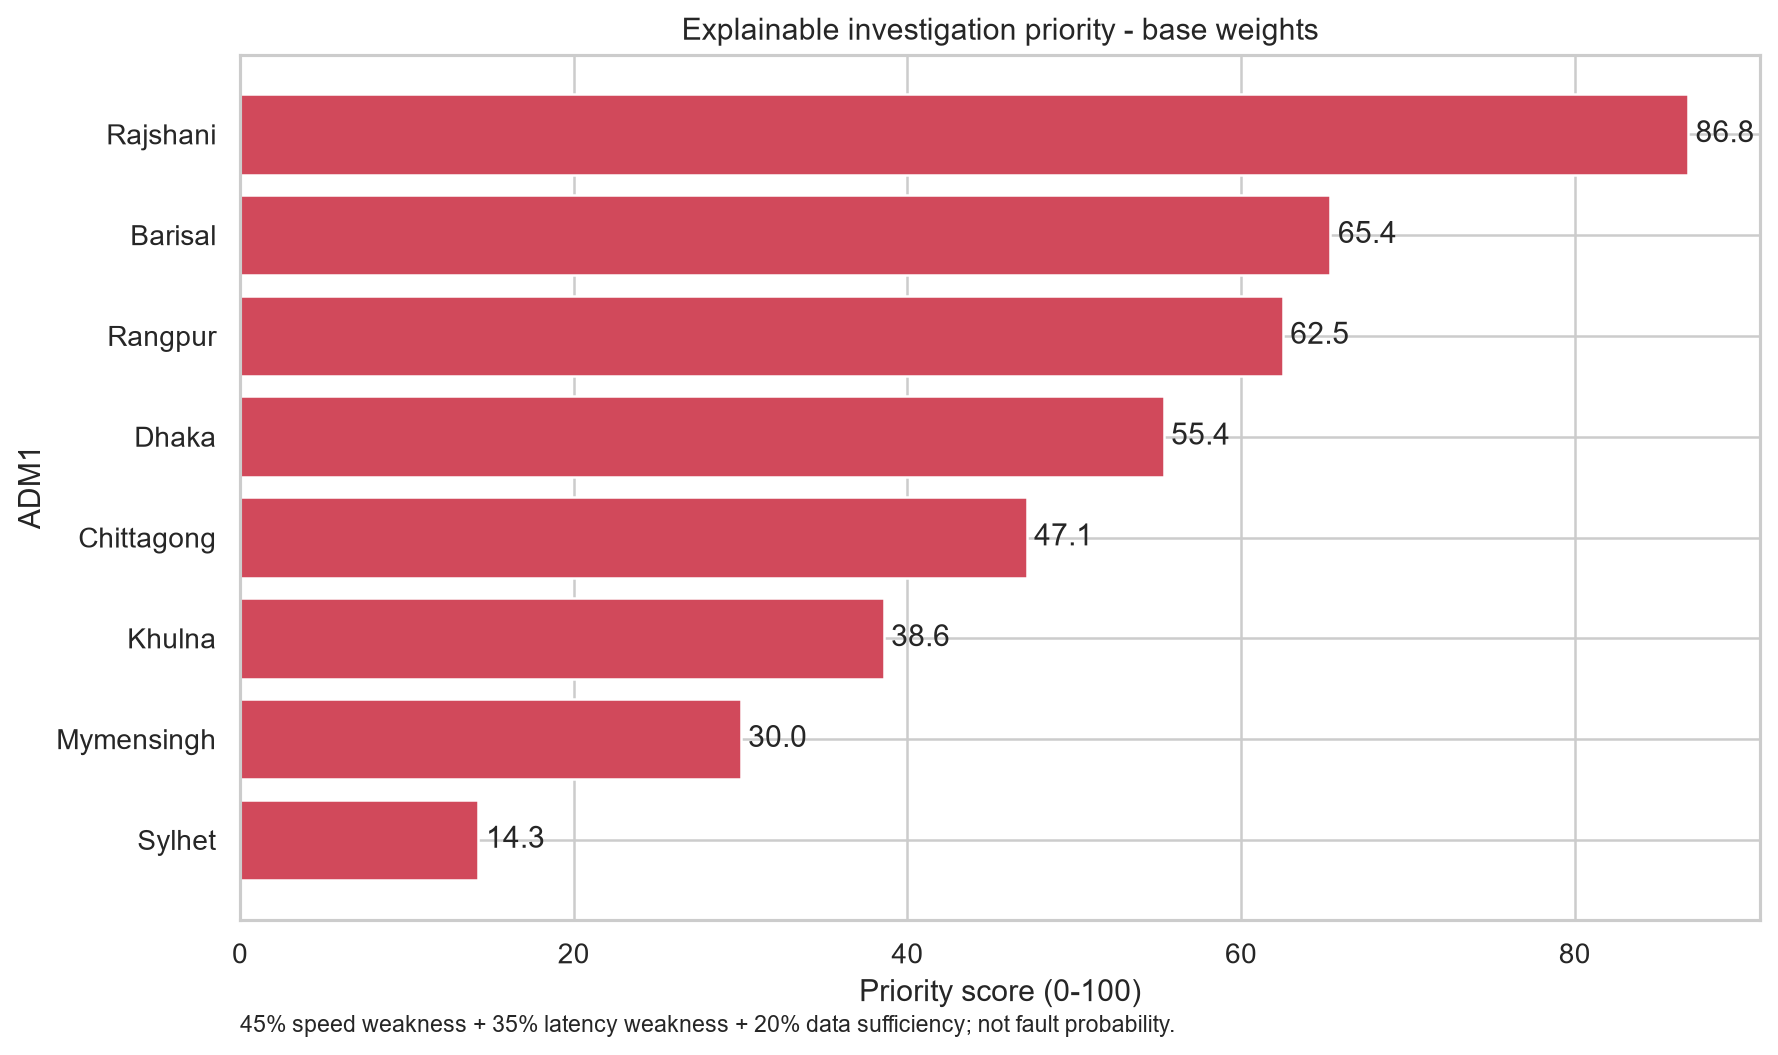

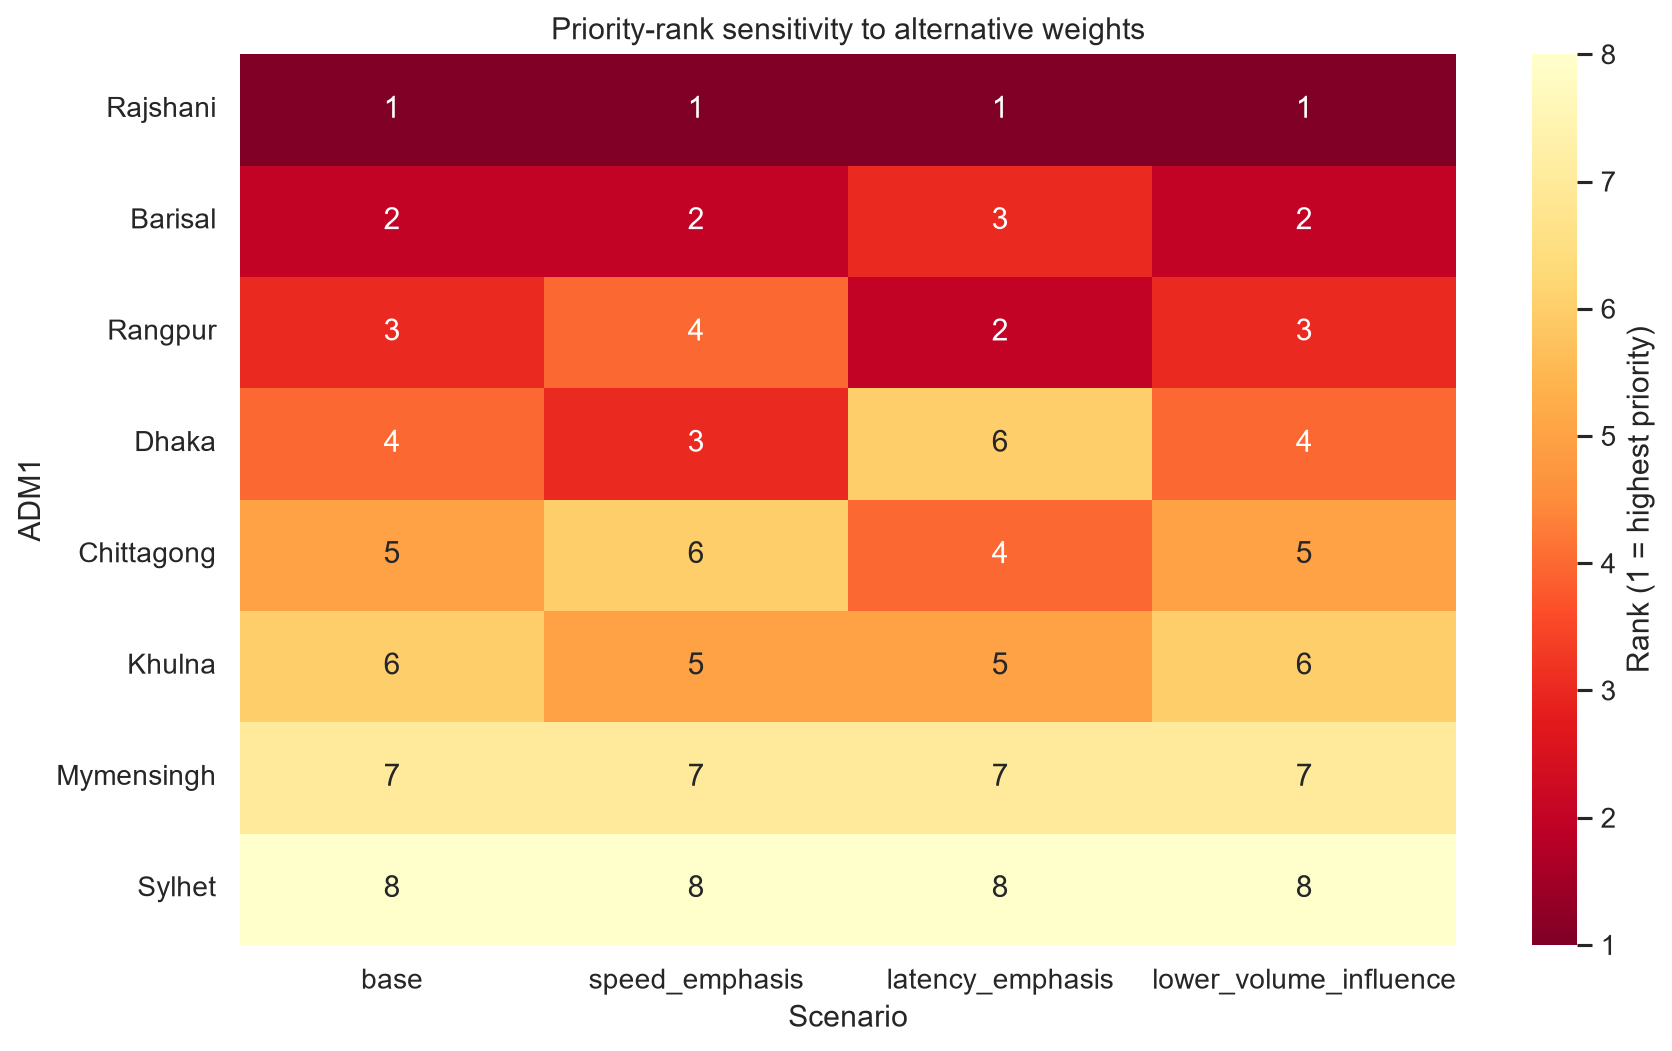

In [5]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/scoring/01_priority_score.png')))
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/scoring/02_rank_sensitivity.png')))

## Interpretation checkpoint

Rajshani is the stable first follow-up across the tested preferences. Middle ranks move when speed or latency receives more weight, so rank differences are decision-dependent. The source cannot establish towers, operators, subscribers, population, outages, or causes; operational diagnosis requires additional evidence.